In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from jcamp import readfile
import locale
import yaml

In [2]:
from setup import (
    violet,
    blue,
    green,
    yellow,
    orange,
    red,
    white,
    gray,
    black,
    colors,
    plot_style,
    filepath,
    configuration,
    testing_labels,
    spectral_range,
    absorption_path_length,
    testing_settling_time as settling_time,
    predictor_type,
)
from processing import (
    is_system_settled,
    broaden_spectrum,
    segment_settled_array,
    cm2inch,
    format_number,
)

In [3]:
locale.setlocale(locale.LC_ALL, "en_US.UTF-8")

plt.style.use(plot_style)
plt.rcParams.update(
    {
        "font.size": 8,
        "axes.titlesize": 10,
        "axes.labelsize": 9,
        "xtick.labelsize": 8,
        "ytick.labelsize": 8,
        "legend.fontsize": 8,
        "lines.linewidth": 0.7,
        "patch.linewidth": 0.7,
        "lines.markeredgewidth": 0.7,
        "lines.markersize": 3.5,
        "axes.formatter.use_locale": True,
    }
)

### Load testing datasets

In [4]:
times = []
delays = []
signals = []
spectra = []
absorbances = []
setpoints = []
are_settled = []
are_analyte_free = []

wavenumber = None
spectral_resolution = None
gas_1 = None
gas_2 = None
split_ratio = None
window_type = None
correction_type = None
signal_type = None

if predictor_type != "absorbance":
    raise ValueError(f"Unsupported predictor type: {predictor_type}.")

for label in testing_labels:
    dataset = np.load(filepath / f"{label}.npz")
    metadata = yaml.safe_load((filepath / f"{label}.yaml").read_text())

    if spectral_resolution is None:
        spectral_resolution = metadata["sampling"]["spectral_resolution"]
    elif spectral_resolution != metadata["sampling"]["spectral_resolution"]:
        raise ValueError(f"Spectral resolution mismatch for {label}.")

    time = dataset["time"]
    delay = dataset["delay"]
    signal = dataset["signal"]
    spectrum = dataset["spectrum"]

    if wavenumber is None:
        wavenumber = dataset["wavenumber"]
        spectral_mask = (wavenumber >= spectral_range[0]) & (
            wavenumber <= spectral_range[1]
        )
    elif wavenumber.shape != dataset["wavenumber"].shape:
        raise ValueError(f"Wavenumber mismatch for {label}.")
    elif not np.allclose(wavenumber, dataset["wavenumber"], atol=1e-3):
        raise ValueError(f"Wavenumber mismatch for {label}.")

    if gas_1 is None:
        gas_1 = str(dataset["gas_1"])
    elif gas_1 != str(dataset["gas_1"]):
        raise ValueError(f"Gas 1 mismatch for {label}.")

    if gas_2 is None:
        gas_2 = str(dataset["gas_2"])
    elif gas_2 != str(dataset["gas_2"]):
        raise ValueError(f"Gas 2 mismatch for {label}.")

    if split_ratio is None:
        split_ratio = float(dataset["split_ratio"])
    elif split_ratio != float(dataset["split_ratio"]):
        raise ValueError(f"Split ratio mismatch for {label}.")

    if dataset["type"] == "twins":
        if window_type is None:
            window_type = str(dataset["window_type"])
        elif window_type != str(dataset["window_type"]):
            raise ValueError(f"Window type mismatch for {label}.")

        if correction_type is None:
            correction_type = str(dataset["correction_type"])
        elif correction_type != str(dataset["correction_type"]):
            raise ValueError(f"Correction type mismatch for {label}.")

        if signal_type is None:
            signal_type = str(dataset["signal_type"])
        elif signal_type != str(dataset["signal_type"]):
            raise ValueError(f"Signal type mismatch for {label}.")

    setpoint_0 = dataset["setpoint_0"]
    setpoint_1 = dataset["setpoint_1"]
    setpoint_2 = dataset["setpoint_2"]
    setpoint = np.stack(
        [
            np.mean(setpoint_0, axis=1),
            np.mean(setpoint_1, axis=1),
            np.mean(setpoint_2, axis=1),
        ],
        axis=1,
    )

    time_offset = np.max(np.concatenate(times)) if times else 0
    time = np.min(time, axis=1) + time_offset

    is_settled = is_system_settled(time, setpoint_1, setpoint_2, settling_time)
    is_analyte_free = (
        np.all((setpoint_0 != 0) & (setpoint_1 == 0) & (setpoint_2 == 0), axis=1)
        & is_settled
    )

    if not np.any(is_analyte_free):
        raise ValueError(f"No analyte-free spectra found for {label}.")

    absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))

    times.append(time)
    delays.append(delay)
    signals.append(signal)
    spectra.append(spectrum)
    absorbances.append(absorbance)
    setpoints.append(setpoint)
    are_settled.append(is_settled)
    are_analyte_free.append(is_analyte_free)

times = np.concatenate(times, axis=0)
delays = np.concatenate(delays, axis=0)
signals = np.concatenate(signals, axis=0)
spectra = np.concatenate(spectra, axis=0)
absorbances = np.concatenate(absorbances, axis=0)
setpoints = np.concatenate(setpoints, axis=0)
are_settled = np.concatenate(are_settled, axis=0)
are_analyte_free = np.concatenate(are_analyte_free, axis=0)

gases = (gas_1, gas_2)

C:\Users\eherkert\AppData\Local\Temp\ipykernel_11004\3746294221.py:101: RuntimeWarning: invalid value encountered in log10
  absorbance = -np.log10(spectrum / np.mean(spectrum[is_analyte_free, :], axis=0))


In [5]:
number_spectra, number_wavenumbers = np.shape(absorbances)
number_gases = len(gases)
gas_labels = {"isopropanol": "iPrOH", "ethanol": "EtOH"}

print(f"Datasets: {', '.join(testing_labels)}")
print(f"Gases: {gas_labels[gas_1]}, {gas_labels[gas_2]}")
print(
    f"Spectra: {number_spectra} "
    f"({np.sum(are_settled)} are settled, {np.sum(are_analyte_free)} are analyte free)"
)
print(f"Wavenumbers: {number_wavenumbers} at {spectral_resolution} cm^-1 resolution")

Datasets: GRASP26_72F
Gases: iPrOH, EtOH
Spectra: 882 (402 are settled, 210 are analyte free)
Wavenumbers: 98 at 20 cm^-1 resolution


In [6]:
sampling_times = np.diff(times)

sampling_time = np.mean(sampling_times)
sampling_time_se = np.std(sampling_times, ddof=1) / np.sqrt(len(sampling_times))

print(
    f"Sampling time: "
    f"{format_number(sampling_time, sampling_time_se)} +/- "
    f"{format_number(sampling_time_se, sampling_time_se)} s per spectrum"
)

Sampling time: 64.3269 +/- 7.0\cdot10^{-3} s per spectrum


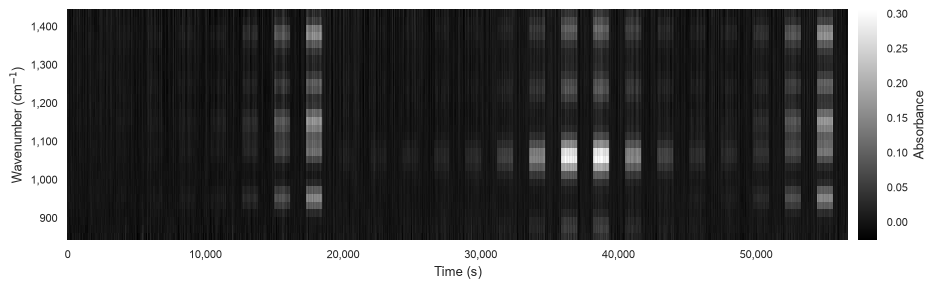

In [7]:
fig, ax = plt.subplots(figsize=(12, 3))

mesh = ax.pcolormesh(
    times,
    wavenumber[spectral_mask],
    absorbances[:, spectral_mask].T,
    cmap="gray",
)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Wavenumber (cm$^{-1}$)")

fig.colorbar(mesh, ax=ax, label="Absorbance", aspect=12, pad=0.01)

### Segment settled spectra

In [8]:
signals_segmented = segment_settled_array(signals, are_settled)
spectra_segmented = segment_settled_array(spectra, are_settled)
absorbances_segmented = segment_settled_array(absorbances, are_settled)
setpoints_segmented = segment_settled_array(setpoints, are_settled)

maximum_isopropanol_index, maximum_ethanol_index = np.argmax(
    np.mean(setpoints_segmented[:, 1:, :], axis=0), axis=1
)
analyte_free_index = np.argmin(
    np.sum(np.mean(setpoints_segmented[:, 1:, :], axis=0), axis=0)
)

index = np.shape(signals_segmented)[0] // 2
signals_sample = signals_segmented[index, :, :]
spectra_sample = spectra_segmented[index, :, :]

absorbances_mean = np.mean(absorbances_segmented, axis=0)
absorbances_std = np.std(absorbances_segmented, axis=0, ddof=1)

### Load reference spectra

In [9]:
wavenumber_nist = {}
absorption_coefficients_nist = {}
for gas in gases:
    data_nist = readfile(Path("NIST", f"{gas}.jdx"))

    if data_nist["yunits"] == "TRANSMITTANCE":
        data_nist["y"] = -np.log10(data_nist["y"])

    wavenumber_nist[gas] = data_nist["x"]
    absorption_coefficients_nist[gas] = broaden_spectrum(
        data_nist["x"],
        data_nist["y"],
        spectral_range,
        spectral_resolution,
        window_type,
    )

    spectral_mask_nist = (wavenumber_nist[gas] >= spectral_range[0]) & (
        wavenumber_nist[gas] <= spectral_range[1]
    )
    wavenumber_nist[gas] = wavenumber_nist[gas][spectral_mask_nist]
    absorption_coefficients_nist[gas] = absorption_coefficients_nist[gas][
        spectral_mask_nist
    ]

In [10]:
absorption_coefficients = []
for gas in gases:
    absorption_coefficients.append(
        np.interp(wavenumber, wavenumber_nist[gas], absorption_coefficients_nist[gas])
    )

absorption_coefficients = np.stack(absorption_coefficients, axis=1)

### Estimate maximum concentrations

In [11]:
maximum_indices = (maximum_isopropanol_index, maximum_ethanol_index)

maximum_concentration_estimates = []
for ii, gas in enumerate(gases):
    design_matrix = np.stack(
        [
            absorption_coefficients[spectral_mask, ii] * absorption_path_length,
        ],
        axis=1,
    )
    coefficients, *_ = np.linalg.lstsq(
        design_matrix,
        absorbances_mean[spectral_mask, maximum_indices[ii]],
        rcond=None,
    )

    maximum_concentration_estimates.append(coefficients[0])

    maximum_concentration = coefficients[0]

    delta_wavenumber = np.mean(np.abs(np.diff(wavenumber[spectral_mask])))
    absorbance_std = absorbances_std[spectral_mask, maximum_indices[ii]]
    integrated_absorbance_std = delta_wavenumber * np.sqrt(np.sum(absorbance_std**2))

    print(
        f"{gas_labels[gas]}: maximum concentration = {maximum_concentration:,.0f} ppm"
    )

    print(
        f"{gas_labels[gas]}: "
        f"integrated absorbance uncertainty = "
        f"{integrated_absorbance_std:.3f} cm^-1"
    )

    print()

maximum_concentration_estimates = np.array(maximum_concentration_estimates)

iPrOH: maximum concentration = 10,565 ppm
iPrOH: integrated absorbance uncertainty = 1.006 cm^-1

EtOH: maximum concentration = 11,600 ppm
EtOH: integrated absorbance uncertainty = 0.825 cm^-1



### Estimate interferogram contrast

In [12]:
signal_analyte_free = signals_sample[:, analyte_free_index]
s_min = np.min(signal_analyte_free)
s_max = np.max(signal_analyte_free)

contrast = (s_max - s_min) / (s_max + s_min)

print(f"Contrast = {100 * contrast:,.3f}%")

Contrast = 49.613%


### Plot basic characterization

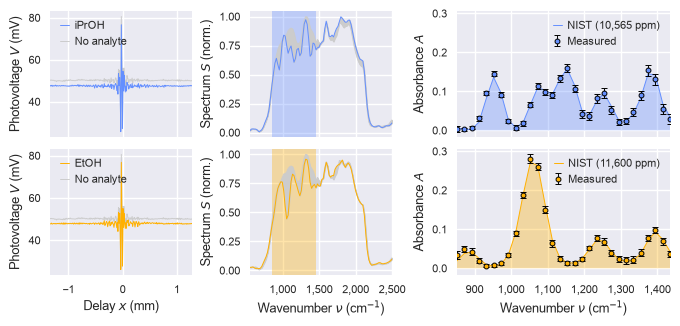

In [13]:
fig, axs = plt.subplots(
    2,
    3,
    figsize=cm2inch((17, 8)),
    constrained_layout=True,
    gridspec_kw={"width_ratios": [1, 1, 1.5]},
)

### isopropanol interferogram ###
axs[0, 0].plot(
    delays[0, :],
    1e3 * signals_sample[:, maximum_isopropanol_index],
    color=blue,
    label="iPrOH",
    zorder=10,
)
axs[0, 0].plot(
    delays[0, :],
    1e3 * signals_sample[:, analyte_free_index],
    color=gray,
    label="No analyte",
    zorder=5,
)

axs[0, 0].set_xticklabels([])
axs[0, 0].set_ylabel("Photovoltage $V$ (mV)")
legend = axs[0, 0].legend(handlelength=0.8, handletextpad=0.5, loc="upper left")
legend.set_zorder(20)

### ethanol interferogram ###
axs[1, 0].plot(
    delays[0, :],
    1e3 * signals_sample[:, maximum_ethanol_index],
    color=yellow,
    label="EtOH",
    zorder=10,
)
axs[1, 0].plot(
    delays[0, :],
    1e3 * signals_sample[:, analyte_free_index],
    color=gray,
    label="No analyte",
    zorder=5,
)

axs[1, 0].set_xlabel("Delay $x$ (mm)")
axs[1, 0].set_ylabel("Photovoltage $V$ (mV)")
legend = axs[1, 0].legend(handlelength=0.8, handletextpad=0.5, loc="upper left")
legend.set_zorder(20)

### isopropanol spectrum ###
axs[0, 1].plot(
    wavenumber,
    spectra_sample[:, maximum_isopropanol_index]
    / spectra_sample[:, analyte_free_index].max(),
    color=blue,
    label="iPrOH",
    zorder=15,
)
axs[0, 1].plot(
    wavenumber,
    spectra_sample[:, analyte_free_index] / spectra_sample[:, analyte_free_index].max(),
    color=gray,
    label="No analyte",
    zorder=10,
)
axs[0, 1].fill_between(
    wavenumber,
    spectra_sample[:, analyte_free_index] / spectra_sample[:, analyte_free_index].max(),
    spectra_sample[:, maximum_isopropanol_index]
    / spectra_sample[:, analyte_free_index].max(),
    color=gray,
    zorder=10,
)

axs[0, 1].axvspan(*spectral_range, edgecolor=None, facecolor=blue + "55", zorder=5)

axs[0, 1].set_xticklabels([])
axs[0, 1].set_ylabel("Spectrum $S$ (norm.)")

### ethanol spectrum ###
axs[1, 1].plot(
    wavenumber,
    spectra_sample[:, maximum_ethanol_index]
    / spectra_sample[:, analyte_free_index].max(),
    color=yellow,
    label="EtOH",
    zorder=15,
)
axs[1, 1].plot(
    wavenumber,
    spectra_sample[:, analyte_free_index] / spectra_sample[:, analyte_free_index].max(),
    color=gray,
    label="No analyte",
    zorder=10,
)
axs[1, 1].fill_between(
    wavenumber,
    spectra_sample[:, analyte_free_index] / spectra_sample[:, analyte_free_index].max(),
    spectra_sample[:, maximum_ethanol_index]
    / spectra_sample[:, analyte_free_index].max(),
    color=gray,
    zorder=10,
)

axs[1, 1].axvspan(*spectral_range, edgecolor=None, facecolor=yellow + "55", zorder=5)

axs[1, 1].set_xlabel("Wavenumber $\\nu$ (cm$^{-1}$)")
axs[1, 1].set_ylabel("Spectrum $S$ (norm.)")

### isopropanol absorbance ###
axs[0, 2].errorbar(
    wavenumber[spectral_mask],
    absorbances_mean[spectral_mask, maximum_isopropanol_index],
    yerr=[absorbances_std[spectral_mask, maximum_isopropanol_index]],
    color=blue,
    ecolor=black,
    markeredgecolor=black,
    fmt="o",
    capsize=2,
    label="Measured",
    zorder=15,
)
axs[0, 2].plot(
    wavenumber[spectral_mask],
    absorption_coefficients[spectral_mask, 0]
    * absorption_path_length
    * maximum_concentration_estimates[0],
    color=blue,
    label=f"NIST ({maximum_concentration_estimates[0]:,.0f} ppm)",
    zorder=10,
)
axs[0, 2].fill_between(
    wavenumber[spectral_mask],
    absorption_coefficients[spectral_mask, 0]
    * absorption_path_length
    * maximum_concentration_estimates[0],
    edgecolor=None,
    facecolor=blue + "55",
    zorder=5,
)

axs[0, 2].set_xticklabels([])
axs[0, 2].set_ylabel("Absorbance $A$")
legend = axs[0, 2].legend(handlelength=0.8, handletextpad=0.5, loc="upper right")
legend.set_zorder(20)

### ethanol absorbance ###
axs[1, 2].errorbar(
    wavenumber[spectral_mask],
    absorbances_mean[spectral_mask, maximum_ethanol_index],
    yerr=[absorbances_std[spectral_mask, maximum_ethanol_index]],
    color=yellow,
    ecolor=black,
    markeredgecolor=black,
    fmt="o",
    capsize=2,
    label=f"Measured",
    zorder=15,
)
axs[1, 2].plot(
    wavenumber[spectral_mask],
    absorption_coefficients[spectral_mask, 1]
    * absorption_path_length
    * maximum_concentration_estimates[1],
    color=yellow,
    label=f"NIST ({maximum_concentration_estimates[1]:,.0f} ppm)",
    zorder=10,
)
axs[1, 2].fill_between(
    wavenumber[spectral_mask],
    absorption_coefficients[spectral_mask, 1]
    * absorption_path_length
    * maximum_concentration_estimates[1],
    edgecolor=None,
    facecolor=yellow + "55",
    zorder=5,
)

axs[1, 2].set_xlabel("Wavenumber $\\nu$ (cm$^{-1}$)")
axs[1, 2].set_ylabel("Absorbance $A$")
axs[0, 2].sharey(axs[1, 2])
legend = axs[1, 2].legend(handlelength=0.8, handletextpad=0.5, loc="upper right")
legend.set_zorder(20)

for ax in axs.ravel():
    ax.margins(0, 0.05)

filepath = Path("..", "Figures", f"02-basic-characterization-{configuration}.svg")
fig.savefig(filepath, dpi=600)